---
title: "Time Series Analysis for Transportation"
description: " "
date: 2024-11-11
categories: [Time Series Analysis]
image: images/transportation.jpg
---

<ol class="breadcrumb">
  <li class="breadcrumb-item"><a href="../../index.qmd">Home</a></li>
  <li class="breadcrumb-item"><a href="../ai/index.qmd">Artificial Intelligence Projects</a></li>
  <li class="breadcrumb-item active">Time Series Analysis for Transportation</li>
</ol>

## Overview

This is a hands-on implementation of ARIMA models using a fictious study case and sythetic datasets from Datacamp.

Here's the story:

**[E-mail from Mr. X]**

To the Office of Transportation at The 22nd Century Sporting League,

After our inaugural 2101 season, The League is looking for ways to optimize our game scheduling process and costs.  We know that transportation logistics are a major variable to consider during scheduling, and as such, we’ve got a few questions for you. 

**Our primary areas of focus are surrounding the number of jets that The League needs to own, and the cost of fuel for those flights. If we want The League to enjoy continued success, we'll need to make sure we manage transportation costs.**

We’re sharing schedule data for the upcoming 2102 season.  On each row, you’ll find information about which teams are needing to travel to their next set of games, the time the flight will likely depart (based on our estimations of gameplay durations) and the time the flight will likely land. 

Additionally, we're also providing the fuel price that was paid each day during this past 2101 season. The fuel price fluctuates over time, but we're hoping you'll be able to project it to the future to help with the analysis.

### The Data

- team_flights.csv

| Column     | Description              |
|------------|--------------------------|
| `team_name` | Official team name |
| `departure_datetime` | Date and Time (in UTC) when the flight will depart |
| `landing_datetime` | Date and Time (in UTC) when the flight will land |
| `travel_distance_miles` | Total travel distance in miles |


- fuel_price.csv

| Column     | Description              |
|------------|--------------------------|
| `date` | Date when the fuel price was recorded |
| `fuel_price` | Corresponding fuel price (in $ per gallon) |

[<i class="bi bi-download"></i> Download Datasets (.zip)](data/transportation.zip){.btn .btn-secondary role="button" download="" target="_blank}

### Important Assumptions

- Assume that each team’s jet fills up with fuel equivalent to 1 gallon per mile-of-travel 
- Assume that the jet is fueled on the day the travel departs (and thus can use the fuel price corresponding to the departure date)

## Install and Import Packages

In [ ]:
%pip install --upgrade -q matplotlib numpy pandas statsmodels

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Load Dataset

In [36]:
team_flights_df = pd.read_csv('data/team_flights.csv')
fuel_prices_2101_df = pd.read_csv('data/fuel_prices_2101.csv')

In [22]:
team_flights_df

,team_name,departure_datetime,landing_datetime,travel_distance_miles
0,Agile Antelopes,2102-04-06 21:37:00,2102-04-07 00:35:57,1491.250000
1,Agile Antelopes,2102-04-10 23:57:00,2102-04-11 01:35:40,822.222222
2,Agile Antelopes,2102-04-14 00:29:00,2102-04-14 05:02:55,2282.638889
3,Agile Antelopes,2102-04-21 03:31:00,2102-04-21 05:23:09,934.583333
4,Agile Antelopes,2102-04-24 22:23:00,2102-04-25 00:25:50,1023.611111
...,...,...,...,...
1140,Diligent Data Scientists,2102-09-05 01:22:00,2102-09-05 03:14:19,935.972222
1141,Diligent Data Scientists,2102-09-07 23:56:00,2102-09-08 04:26:26,2253.611111
1142,Diligent Data Scientists,2102-09-18 22:20:00,2102-09-18 23:00:50,340.277778
1143,Diligent Data Scientists,2102-09-23 03:37:00,2102-09-23 05:40:32,1029.444444


In [23]:
team_flights_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1145 entries, 0 to 1144
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   team_name              1145 non-null   str    
 1   departure_datetime     1145 non-null   str    
 2   landing_datetime       1145 non-null   str    
 3   travel_distance_miles  1145 non-null   float64
dtypes: float64(1), str(3)
memory usage: 35.9 KB


In [24]:
fuel_prices_2101_df

,date,price
0,2101-01-01,0.97
1,2101-01-02,0.87
2,2101-01-03,0.87
3,2101-01-04,0.97
4,2101-01-05,1.10
...,...,...
360,2101-12-27,1.33
361,2101-12-28,1.46
362,2101-12-29,1.51
363,2101-12-30,1.46


In [25]:
fuel_prices_2101_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    365 non-null    str    
 1   price   365 non-null    float64
dtypes: float64(1), str(1)
memory usage: 5.8 KB


## Data Preprocessing and EDA

In [39]:
team_flights_df['departure_datetime'] = pd.to_datetime(team_flights_df['departure_datetime'])
team_flights_df['landing_datetime'] = pd.to_datetime(team_flights_df['landing_datetime'])

fuel_prices_2101_df['date'] = pd.to_datetime(fuel_prices_2101_df['date'])
fuel_prices_2101_df = fuel_prices_2101_df.set_index('date')

In [41]:
team_flights_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1145 entries, 0 to 1144
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   team_name              1145 non-null   str           
 1   departure_datetime     1145 non-null   datetime64[us]
 2   landing_datetime       1145 non-null   datetime64[us]
 3   travel_distance_miles  1145 non-null   float64       
dtypes: datetime64[us](2), float64(1), str(1)
memory usage: 35.9 KB


In [48]:
team_flights_df

,team_name,departure_datetime,landing_datetime,travel_distance_miles
0,Agile Antelopes,2102-04-06 21:37:00,2102-04-07 00:35:57,1491.250000
1,Agile Antelopes,2102-04-10 23:57:00,2102-04-11 01:35:40,822.222222
2,Agile Antelopes,2102-04-14 00:29:00,2102-04-14 05:02:55,2282.638889
3,Agile Antelopes,2102-04-21 03:31:00,2102-04-21 05:23:09,934.583333
4,Agile Antelopes,2102-04-24 22:23:00,2102-04-25 00:25:50,1023.611111
...,...,...,...,...
1140,Diligent Data Scientists,2102-09-05 01:22:00,2102-09-05 03:14:19,935.972222
1141,Diligent Data Scientists,2102-09-07 23:56:00,2102-09-08 04:26:26,2253.611111
1142,Diligent Data Scientists,2102-09-18 22:20:00,2102-09-18 23:00:50,340.277778
1143,Diligent Data Scientists,2102-09-23 03:37:00,2102-09-23 05:40:32,1029.444444


In [42]:
fuel_prices_2101_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 365 entries, 2101-01-01 to 2101-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   price   365 non-null    float64
dtypes: float64(1)
memory usage: 5.7 KB


In [43]:
fuel_prices_2101_df

,price
date,
2101-01-01,0.97
2101-01-02,0.87
2101-01-03,0.87
2101-01-04,0.97
2101-01-05,1.10
...,...
2101-12-27,1.33
2101-12-28,1.46
2101-12-29,1.51


In [44]:
fuel_prices_2101_df.index

DatetimeIndex(['2101-01-01', '2101-01-02', '2101-01-03', '2101-01-04',
               '2101-01-05', '2101-01-06', '2101-01-07', '2101-01-08',
               '2101-01-09', '2101-01-10',
               ...
               '2101-12-22', '2101-12-23', '2101-12-24', '2101-12-25',
               '2101-12-26', '2101-12-27', '2101-12-28', '2101-12-29',
               '2101-12-30', '2101-12-31'],
              dtype='datetime64[us]', name='date', length=365, freq=None)

In [45]:
fuel_prices_2101_df.index = pd.DatetimeIndex(fuel_prices_2101_df.index.values).to_period('D')

In [46]:
fuel_prices_2101_df.index

PeriodIndex(['2101-01-01', '2101-01-02', '2101-01-03', '2101-01-04',
             '2101-01-05', '2101-01-06', '2101-01-07', '2101-01-08',
             '2101-01-09', '2101-01-10',
             ...
             '2101-12-22', '2101-12-23', '2101-12-24', '2101-12-25',
             '2101-12-26', '2101-12-27', '2101-12-28', '2101-12-29',
             '2101-12-30', '2101-12-31'],
            dtype='period[D]', length=365)

## Analysis Goals 1

We're interested in the maximum number of jets that The League needs to own. 

Naively, The League can prepare the number of jets that equals to number of the total flights in the season (1145 flights). However, of course, it is not the optimal solution.

Example:

To solve this problem, we can check at each of those timestamps in time_flights_df whether the flight is currently in progress.

Let's create a time-series graph that shows how many teams will be “in flight” throughout the 2102 season. Use this graphic to tell us the maximum number of teams simultaneously in flight.

Max # in flight: 19


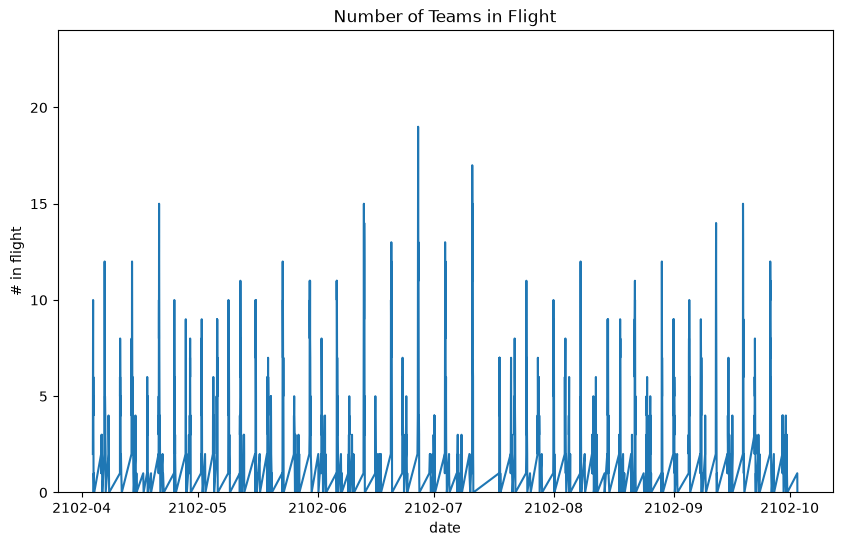

In [78]:
# first we'll want to know the minimum time between any two unique flight event times in the season
# to do this we first create a single array of times
all_datetimes = pd.concat([team_flights_df['departure_datetime'], team_flights_df['landing_datetime']])

# select unique datetimes to list
all_datetimes = list(set(all_datetimes))

# convert to data frame
in_flight_df = pd.DataFrame({'date':sorted(all_datetimes), # sort the datetimes in ascending order
                             'in_flight':0})

# iterate through each known flight, and increment corresponding rows of in_flight_df
for index, flight in team_flights_df.iterrows():
    in_flight_df.loc[(in_flight_df['date']>=flight['departure_datetime']) &
                     (in_flight_df['date']<flight['landing_datetime']),'in_flight'] += 1

# Plot 
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(in_flight_df['date'], in_flight_df['in_flight'])
ax.set_ylim(0, max(in_flight_df['in_flight']) + 5)
ax.set_xlabel('date')
ax.set_ylabel('# in flight')
ax.set_title('Number of Teams in Flight')
print('Max # in flight:', max(in_flight_df['in_flight']))
plt.show()

## Analysis Goals 2


Use 2101's jet fuel prices to project jet fuel prices for 2102. Apply these projections to every flight taken by every team to determine the overall fuel spend for 2102. Store your result in a variable named total_fuel_spend_2102_dollars.

<Axes: >

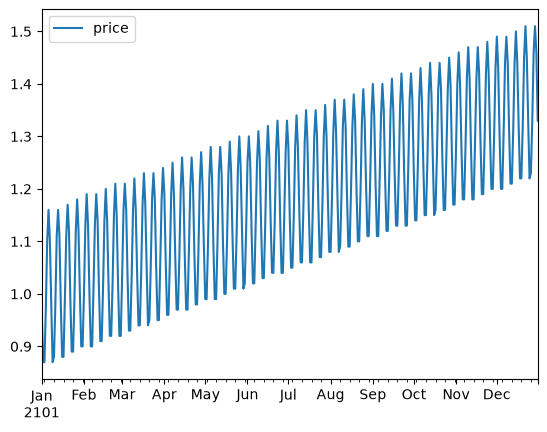

In [79]:
fuel_prices_2101_df.plot()

The data appears to have a seasonality. Let's take a further look.

### ACF and PACF Plot for Non-Seasonal Part

<Axes: >

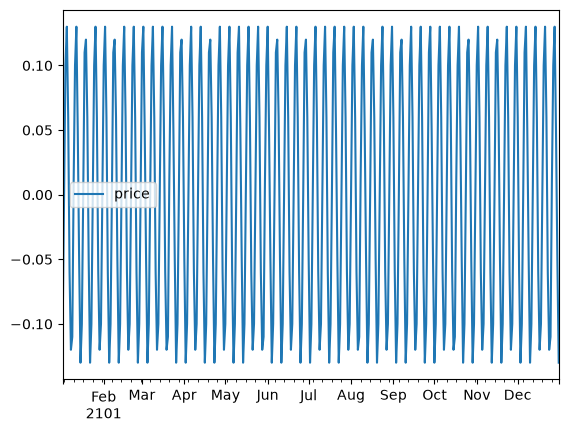

In [ ]:
# first implement differencing to make the data stationary
diff_df = fuel_prices_2101_df.diff().dropna()
diff_df.plot()

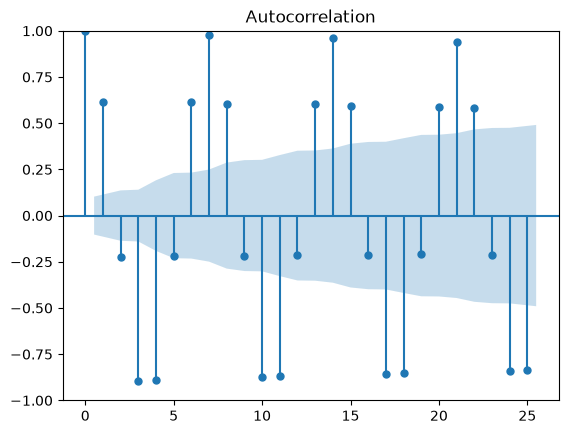

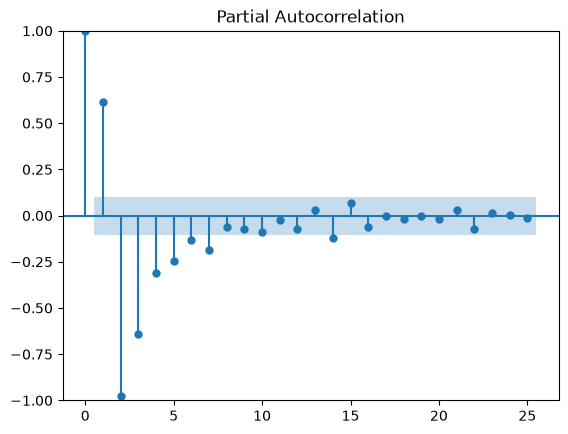

In [99]:
# then, plot the autocorrelation function (acf) and partial autocorrelation function (pacf) 
# to determine the order of ARIMA model, also the number of time steps per cycle (S)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(diff_df, lags=25)
plot_pacf(diff_df, lags=25)
plt.show()

The fuel price data has seasonality with the number of time steps per cycle is $S = 7$.

This means the appropriate model for forecasting the fuel price is SARIMA model. 

So that, we need the value of parameters:
- p, q for non-seasonal part. Note that we have already used d = 1 for the differencing.
- P, D, Q for seasonal part. For the D parameter, notice that the fuel price data has stable amplitude between the baseline and peak of seasonality. Therefore, let's use D = 0.

Based on the ACF and PACF plots above, here are the candidates for p and q:
- $p = 1 \text{ or } 2$: Suggested by the significant spikes at lags 1 and 2 in the PACF plot.
- $q = 1, 2 \text{ or } 3$: Suggested by the significant spikes at lags 1 through 3 in the ACF plot.

Now, let's find the candidates for P and Q using the same dataframe with differencing for $\text{lags} = S, 2S, 3S, ...$

### ACF and PACF Plot for Seasonal Part

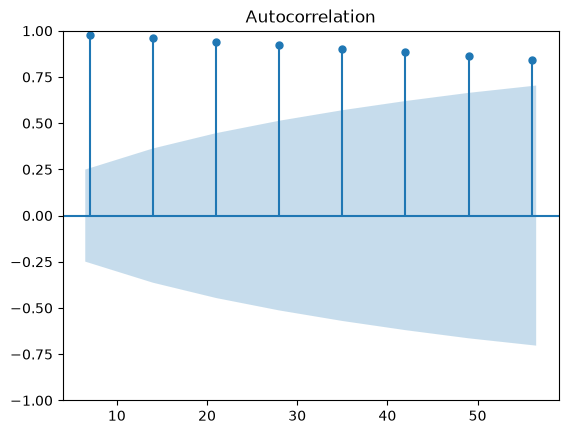

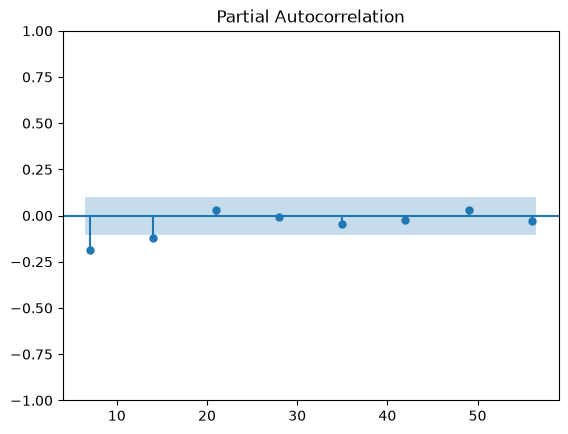

In [97]:
plot_acf(diff_df, lags=[7, 14, 21, 28, 35, 42, 49, 56])
plot_pacf(diff_df, lags=[7, 14, 21, 28, 35, 42, 49, 56])
plt.show()

Based on the plots above, we can see that there is a decay in ACF plot and a cut-off in PACF plot.

These results are indicating the AR-only model, with:
- $P = 1 \text{ or } 2$: Indicated by the sharp cut-off at the first or second seasonal lag ($7$) in the PACF plot, while the seasonal ACF tails off.
- $Q = 0$.

### Selecting The Best Parameters Candidates Using AIC Comparation

To select the best paramaters among the candidates of parameters values, we can use AIC comparation.

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

AIC = {}

for p in range(1, 3):
    for q in range(1, 4):
        for P in range(1, 3):
            model = SARIMAX(fuel_prices_2101_df,
                            order=(p, 1, q),             # for linear growth term
                            seasonal_order=(P, 0, 0, 7)  # for 7 day periodicity
                            )
            result = model.fit()
            AIC[(p, q, P)] = result.aic

for p, q, P in AIC:
    print(f"SARIMA ({p},1,{q}) x ({P},0,0,7) - AIC: {AIC[(p,q,P)]}")

C:\Users\HYPE AMD\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\HYPE AMD\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\HYPE AMD\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\HYPE AMD\AppData\Local\Packages\PythonSoftwareFou

SARIMA (1,1,1) x (1,0,0,7) - AIC: -2820.7311073159
SARIMA (1,1,1) x (2,0,0,7) - AIC: -2874.323897051524
SARIMA (1,1,2) x (1,0,0,7) - AIC: -2819.6958595480196
SARIMA (1,1,2) x (2,0,0,7) - AIC: -2795.4093238640544
SARIMA (1,1,3) x (1,0,0,7) - AIC: -2818.3447812568297
SARIMA (1,1,3) x (2,0,0,7) - AIC: -2884.4329128949726
SARIMA (2,1,1) x (1,0,0,7) - AIC: -2819.88276805261
SARIMA (2,1,1) x (2,0,0,7) - AIC: -2848.561998060254
SARIMA (2,1,2) x (1,0,0,7) - AIC: -2593.57006120841
SARIMA (2,1,2) x (2,0,0,7) - AIC: -2661.343793974922
SARIMA (2,1,3) x (1,0,0,7) - AIC: -2810.146201925937
SARIMA (2,1,3) x (2,0,0,7) - AIC: -2887.2338148395866


C:\Users\HYPE AMD\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


From the results above, the best parameters are:
$$p = 2, d = 1, q = 3, P = 2, D = 0, Q = 0, S = 7,$$
with $AIC = -2887.23$ (most negative).

### Fit The Best Model

In [101]:
# initialize SARIMAX model with selected parameters
model = SARIMAX(fuel_prices_2101_df,
              order=(2, 1, 3),             # for linear growth term
              seasonal_order=(2, 0, 0, 7)  # for 7 day periodicity
              )

# fit the model to the data
result = model.fit()

C:\Users\HYPE AMD\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [176]:
# forecast fuel prices for 2102
forecast = result.get_forecast(steps=365)  # forecast prices for 365 days in 2102
mean_forecast = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

In [109]:
mean_forecast

2102-01-01    1.229842
2102-01-02    1.235831
2102-01-03    1.335892
2102-01-04    1.465821
2102-01-05    1.519822
                ...   
2102-12-27    1.813876
2102-12-28    1.859531
2102-12-29    1.803326
2102-12-30    1.679897
2102-12-31    1.584557
Freq: D, Name: predicted_mean, Length: 365, dtype: float64

In [179]:
confidence_intervals

,lower price,upper price
2102-01-01,1.221592,1.238091
2102-01-02,1.227578,1.244085
2102-01-03,1.327636,1.344147
2102-01-04,1.457565,1.474076
2102-01-05,1.511567,1.528078
...,...,...
2102-12-27,1.723026,1.904726
2102-12-28,1.768677,1.950385
2102-12-29,1.712392,1.894260
2102-12-30,1.588666,1.771128


### Plot Results

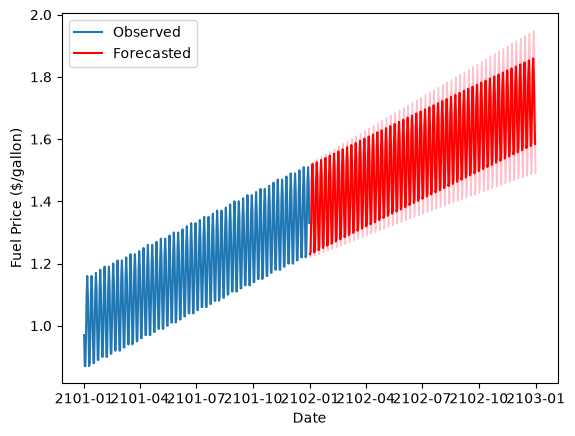

In [183]:
# plot the forecasted fuel prices for 2102
plt.plot(fuel_prices_2101_df.index.to_timestamp().date, fuel_prices_2101_df['price'], label='Observed')
plt.plot(mean_forecast.index.to_timestamp().date, mean_forecast.values, label='Forecasted', color='r')
plt.fill_between(mean_forecast.index, confidence_intervals.loc[:,'lower price'], confidence_intervals.loc[:,'upper price'], color='pink')
plt.xlabel('Date')
plt.ylabel('Fuel Price ($/gallon)')
plt.legend()
plt.show()

In [128]:
# convert to a dataframe
fuel_prices_2102_forecast_df = pd.DataFrame(data={"date": mean_forecast.index, 
                                          "price":mean_forecast.values})

fuel_prices_2102_forecast_df 

,date,price
0,2102-01-01,1.229842
1,2102-01-02,1.235831
2,2102-01-03,1.335892
3,2102-01-04,1.465821
4,2102-01-05,1.519822
...,...,...
360,2102-12-27,1.813876
361,2102-12-28,1.859531
362,2102-12-29,1.803326
363,2102-12-30,1.679897


In [124]:
fuel_prices_2102_forecast_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype    
---  ------  --------------  -----    
 0   date    365 non-null    period[D]
 1   price   365 non-null    float64  
dtypes: float64(1), period[D](1)
memory usage: 5.8 KB


In [118]:
# now, apply to the flight data
# first, extract only the date part from the departure datetime
team_flights_df['date'] = team_flights_df['departure_datetime'].dt.date

team_flights_df

,team_name,departure_datetime,landing_datetime,travel_distance_miles,date
0,Agile Antelopes,2102-04-06 21:37:00,2102-04-07 00:35:57,1491.250000,2102-04-06
1,Agile Antelopes,2102-04-10 23:57:00,2102-04-11 01:35:40,822.222222,2102-04-10
2,Agile Antelopes,2102-04-14 00:29:00,2102-04-14 05:02:55,2282.638889,2102-04-14
3,Agile Antelopes,2102-04-21 03:31:00,2102-04-21 05:23:09,934.583333,2102-04-21
4,Agile Antelopes,2102-04-24 22:23:00,2102-04-25 00:25:50,1023.611111,2102-04-24
...,...,...,...,...,...
1140,Diligent Data Scientists,2102-09-05 01:22:00,2102-09-05 03:14:19,935.972222,2102-09-05
1141,Diligent Data Scientists,2102-09-07 23:56:00,2102-09-08 04:26:26,2253.611111,2102-09-07
1142,Diligent Data Scientists,2102-09-18 22:20:00,2102-09-18 23:00:50,340.277778,2102-09-18
1143,Diligent Data Scientists,2102-09-23 03:37:00,2102-09-23 05:40:32,1029.444444,2102-09-23


In [125]:
team_flights_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1145 entries, 0 to 1144
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   team_name              1145 non-null   str           
 1   departure_datetime     1145 non-null   datetime64[us]
 2   landing_datetime       1145 non-null   datetime64[us]
 3   travel_distance_miles  1145 non-null   float64       
 4   date                   1145 non-null   object        
dtypes: datetime64[us](2), float64(1), object(1), str(1)
memory usage: 44.9+ KB


In [170]:
print(fuel_prices_2102_forecast_df['date'].dt.to_timestamp().dt.date)

0      2102-01-01
1      2102-01-02
2      2102-01-03
3      2102-01-04
4      2102-01-05
          ...    
360    2102-12-27
361    2102-12-28
362    2102-12-29
363    2102-12-30
364    2102-12-31
Name: date, Length: 365, dtype: object


In [171]:
# then, join fuel_prices DataFrame based on the date
fuel_prices_2102_forecast_df['date'] = fuel_prices_2102_forecast_df['date'].dt.to_timestamp().dt.date
fuel_prices_2102_forecast_df = fuel_prices_2102_forecast_df.set_index('date')
merged_df = team_flights_df.join(fuel_prices_2102_forecast_df, on='date', how='left')

merged_df

,team_name,departure_datetime,landing_datetime,travel_distance_miles,date,price
0,Agile Antelopes,2102-04-06 21:37:00,2102-04-07 00:35:57,1491.250000,2102-04-06,1.608313
1,Agile Antelopes,2102-04-10 23:57:00,2102-04-11 01:35:40,822.222222,2102-04-10,1.334504
2,Agile Antelopes,2102-04-14 00:29:00,2102-04-14 05:02:55,2282.638889,2102-04-14,1.560950
3,Agile Antelopes,2102-04-21 03:31:00,2102-04-21 05:23:09,934.583333,2102-04-21,1.567660
4,Agile Antelopes,2102-04-24 22:23:00,2102-04-25 00:25:50,1023.611111,2102-04-24,1.348489
...,...,...,...,...,...,...
1140,Diligent Data Scientists,2102-09-05 01:22:00,2102-09-05 03:14:19,935.972222,2102-09-05,1.581029
1141,Diligent Data Scientists,2102-09-07 23:56:00,2102-09-08 04:26:26,2253.611111,2102-09-07,1.755502
1142,Diligent Data Scientists,2102-09-18 22:20:00,2102-09-18 23:00:50,340.277778,2102-09-18,1.494317
1143,Diligent Data Scientists,2102-09-23 03:37:00,2102-09-23 05:40:32,1029.444444,2102-09-23,1.587862


In [ ]:
# now, alculate the fuel cost for flights
# multiply price per mile
merged_df['fuel_cost_total'] = merged_df['price'] * merged_df['travel_distance_miles']

In [184]:
# now, calculate the overall fuel cost
total_fuel_spend_2102_dollars = merged_df['fuel_cost_total'].sum()
print(f'Forecasted fuel spend for 2102 Season: ${total_fuel_spend_2102_dollars}')

Forecasted fuel spend for 2102 Season: $1865575.383283509


## Conclusions

- The League needs to own **19 jets**.
- The forecasted fuel spend for 2102 Season: **$1865575.383283509**